# 3. Structure volumes

Segmentations are often used to measure volumes, for example of the hippocampus or the ventricles.
Here the volumes from the 45-class U-Net are compared with the FreeSurfer volumes on the test subjects.
Dice and volume agreement are not the same thing: a segmentation can have a lower Dice but still get the
total volume right, or the other way round.

Run notebook 2 first: this one uses its test results. Runs on CPU.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q monai nibabel

import os, sys, zipfile
DRIVE = '/content/drive/MyDrive'

# the wbseg code: use the folder in My Drive, or unpack wbseg.zip there the first time
if not os.path.exists(f'{DRIVE}/wbseg/__init__.py'):
    if os.path.exists(f'{DRIVE}/wbseg.zip'):
        zipfile.ZipFile(f'{DRIVE}/wbseg.zip').extractall(DRIVE)
        print('unpacked wbseg.zip into My Drive')
    else:
        raise SystemExit('wbseg not found. Upload wbseg.zip to My Drive (not inside any folder) and run this cell again.')
sys.path.insert(0, DRIVE)
import wbseg
print('using wbseg from', os.path.dirname(wbseg.__file__))

OUT_DIR = f'{DRIVE}/wbseg_outputs'   # results and figures are saved here
os.makedirs(OUT_DIR, exist_ok=True)
os.chdir(OUT_DIR)

Mounted at /content/drive
using wbseg from /content/drive/MyDrive/wbseg


In [2]:
IMAGE_DIR = "/content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Image_Folder"
LABEL_DIR = "/content/drive/MyDrive/OASIS3_Dataset_Part4-20240506T062954Z-001/OASIS3_Dataset_Part4/Label_Folder"
LUT_PATH = "/content/drive/MyDrive/FreeSurferColorLUT.txt"   # optional, only for FreeSurfer colours
RUN_DIR = "/content/drive/MyDrive/wbseg_outputs/runs"         # checkpoints, best models and test predictions

if not os.path.exists(LUT_PATH):
    LUT_PATH = None
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

from wbseg.labels import FULL_LABELS
from wbseg.volumes import agreement, volume_table
from wbseg import plots

if not os.path.exists("results/test_dice_full.csv"):
    raise SystemExit("results/test_dice_full.csv not found in " + os.getcwd() +
                     "\nRun notebook 02 to the end first: it trains the models and writes the test results.")
results = pd.read_csv("results/test_dice_full.csv")
print(results["id"].nunique(), "test subjects")

30 test subjects


## Agreement per structure

In [4]:
agree = agreement(results)
agree.to_csv("results/volume_agreement.csv", index=False)
agree.round(3)

,label,structure,mean_volume_ml,pearson_r,mean_diff_pct,mean_abs_diff_pct
21,42,Right-Cerebral-Cortex,207.045,0.899,7.232,7.353
1,3,Left-Cerebral-Cortex,202.246,0.920,7.204,7.204
20,41,Right-Cerebral-White-Matter,190.629,0.895,-3.086,6.679
0,2,Left-Cerebral-White-Matter,189.360,0.930,-3.585,5.778
25,47,Right-Cerebellum-Cortex,45.989,0.971,2.339,2.874
5,8,Left-Cerebellum-Cortex,44.690,0.968,1.565,2.725
12,16,Brain-Stem,19.631,0.957,-2.550,3.428
2,4,Left-Lateral-Ventricle,17.129,1.000,-0.781,2.069
22,43,Right-Lateral-Ventricle,15.285,0.999,-3.118,3.892
24,46,Right-Cerebellum-White-Matter,13.401,0.855,-4.545,6.813


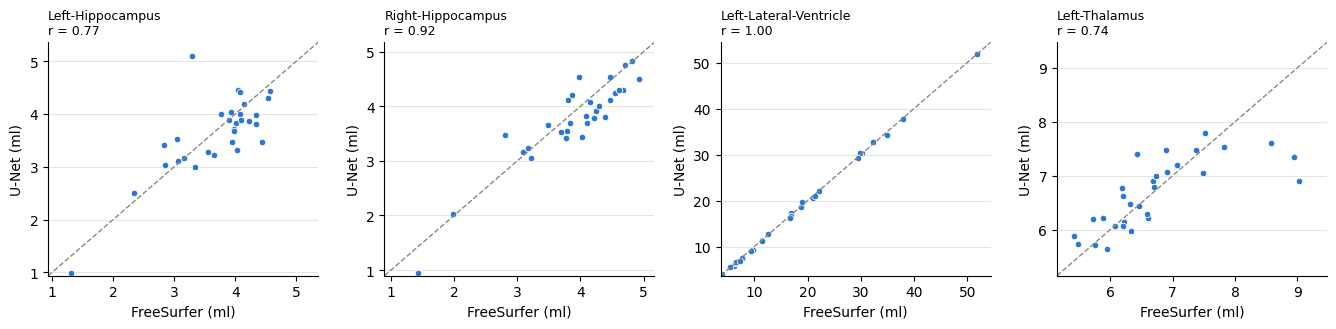

In [5]:
fig = plots.volume_scatter(results, ["Left-Hippocampus", "Right-Hippocampus",
                                     "Left-Lateral-Ventricle", "Left-Thalamus"])
fig.savefig("figures/volume_agreement.png", dpi=150)
plt.show()

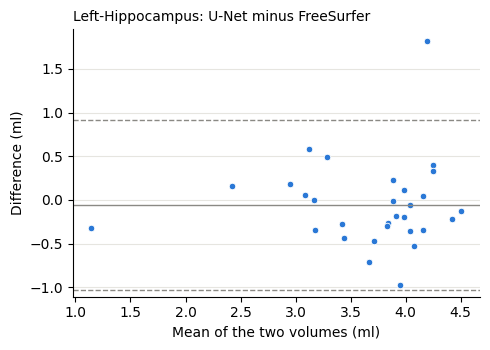

In [6]:
fig = plots.bland_altman(results, "Left-Hippocampus")
fig.savefig("figures/bland_altman_hippocampus.png", dpi=150)
plt.show()

## Volume table for any folder of segmentations

`volume_table` reads every label map in a folder and gives one row per scan and one column per structure,
in millilitres, using the voxel size from each file's header. It works on the U-Net predictions and on
FreeSurfer's own `aseg` files.

In [7]:
table = volume_table(f"{RUN_DIR}/full/test_predictions", FULL_LABELS)
table.to_csv("results/predicted_volumes.csv", index=False)
table.head()

,id,Left-Cerebral-White-Matter,Left-Cerebral-Cortex,Left-Lateral-Ventricle,Left-Inf-Lat-Vent,Left-Cerebellum-White-Matter,Left-Cerebellum-Cortex,Left-Thalamus,Left-Caudate,Left-Putamen,...,Right-vessel,Right-choroid-plexus,WM-hypointensities,non-WM-hypointensities,Optic-Chiasm,CC_Posterior,CC_Mid_Posterior,CC_Central,CC_Mid_Anterior,CC_Anterior
0,OAS30028_MR_d0043,215.815026,225.364027,5.490001,0.350,12.878002,46.624006,7.482001,3.256,5.269001,...,0.120,1.734,1.969000,0.011,0.208,0.870,0.356,0.369,0.254,0.719
1,OAS30036_MR_d0059,201.383024,230.427027,7.248001,0.076,13.176002,52.763006,7.533001,3.394,5.384001,...,0.069,1.984,2.449000,0.004,0.163,1.038,0.435,0.485,0.404,0.762
2,OAS30039_MR_d1203,162.090000,218.014000,22.096000,0.444,13.662000,45.458000,7.606000,4.325,5.195000,...,0.061,2.598,13.808000,0.016,0.264,0.871,0.297,0.238,0.259,0.528
3,OAS30071_MR_d1627,208.869000,223.285000,30.319000,1.843,13.987000,49.223000,7.401000,3.467,4.919000,...,0.099,2.544,18.643000,0.038,0.220,0.910,0.242,0.312,0.332,0.455
4,OAS30074_MR_d2812,182.635022,223.670027,18.616002,0.785,13.005002,47.047006,6.896001,3.239,4.900001,...,0.114,2.746,7.723001,0.010,0.243,0.861,0.330,0.406,0.359,0.878
